In [1]:
from __future__ import annotations
import random
from typing import Sequence, List
import matplotlib.pyplot as plt

In [2]:
class Child:
    _name: str
    _carateristics: tuple[bool, ...]

    def __init__(self, name: str, carateristics: Sequence[bool]):
        self._name = name
        self._carateristics = tuple(carateristics)

    def difference(self, other: Child) -> int:
        return sum(s != o for s, o in zip(self._carateristics, other._carateristics))

    def __str__(self) -> str:
        return f"{self._name}: {self._carateristics}"

    def __repr__(self) -> str:
        return self._name

In [3]:
def fitness(solution: Sequence[Child]) -> int:
    sol = list(solution)
    total_diff = 0
    n = len(sol)
    for i in range(n):
        c1 = sol[i]
        c2 = sol[(i + 1) % n]
        total_diff += c1.difference(c2)
    return total_diff

In [4]:
def canonicalize(solution: List[Child]) -> List[Child]:
    if len(solution) <= 2:
        return solution
    
    if solution[1]._name > solution[-1]._name:
        return [solution[0]] + list(reversed(solution[1:]))
    return solution

In [5]:
def tweak(solution: List[Child]) -> List[Child]:
    candidate = solution.copy()
    i, j = random.sample(range(1, len(candidate)), 2)
    candidate[i], candidate[j] = candidate[j], candidate[i]
    return canonicalize(candidate)

Initial State - Fitness: 230
Right: child_05 | Left: child_08
Step 0002 -> New Best! Fitness: 240
Step 0003 -> New Best! Fitness: 244
Step 0004 -> New Best! Fitness: 248
Step 0013 -> New Best! Fitness: 252
Step 0015 -> New Best! Fitness: 254
Step 0027 -> New Best! Fitness: 258
Step 0028 -> New Best! Fitness: 260
Step 0032 -> New Best! Fitness: 262
Step 0034 -> New Best! Fitness: 264
Step 0040 -> New Best! Fitness: 266
Step 0045 -> New Best! Fitness: 268
Step 0046 -> New Best! Fitness: 270
Step 0059 -> New Best! Fitness: 272
Step 0061 -> New Best! Fitness: 278
Step 0070 -> New Best! Fitness: 282
Step 0082 -> New Best! Fitness: 284
Step 0125 -> New Best! Fitness: 286
Step 0157 -> New Best! Fitness: 288
Step 0175 -> New Best! Fitness: 290
Step 0187 -> New Best! Fitness: 292
Step 0270 -> New Best! Fitness: 294
Step 0425 -> New Best! Fitness: 296
Step 0506 -> New Best! Fitness: 302

Termination per Steady State

Final Fitness: 302
Total Steps: 1306
Circle:
child_00 -> child_21 -> child_12 -

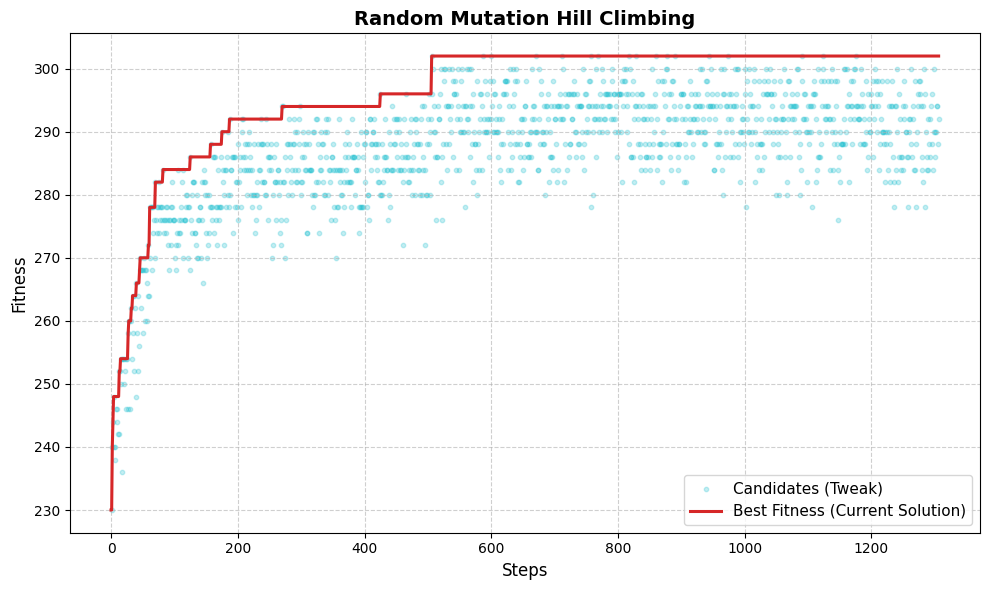

In [6]:

NUM_CHILDREN = 30
NUM_C = 15   

random.seed(42)

all_children: list[Child] = []
for c in range(NUM_CHILDREN):
    name = f"child_{c:02d}"
    features = random.sample([True, False], k=NUM_C, counts=[NUM_C, NUM_C])
    all_children.append(Child(name, features))

FIRST_CHILD = all_children[0]
REST_OF_CHILDREN = all_children[1:].copy()

random.shuffle(REST_OF_CHILDREN)
current_solution = canonicalize([FIRST_CHILD] + REST_OF_CHILDREN)
current_fitness = fitness(current_solution)

print(f"Initial State - Fitness: {current_fitness}")
print(f"Right: {current_solution[1]._name} | Left: {current_solution[-1]._name}")

MAX_STEPS = 5_000
STEADY_STATE_STEPS = 800
last_improvement = 0
step = 0

history_steps: list[int] = [0]
history_best_fitness: list[int] = [current_fitness]

history_candidate_steps: list[int] = []
history_candidate_fitness: list[int] = []

while step < MAX_STEPS:
    step += 1
    
    candidate_solution = tweak(current_solution)
    candidate_fit = fitness(candidate_solution)
    
    history_candidate_steps.append(step)
    history_candidate_fitness.append(candidate_fit)
    
    if candidate_fit > current_fitness:
        current_solution = candidate_solution
        current_fitness = candidate_fit
        last_improvement = step
        print(f"Step {step:04d} -> New Best! Fitness: {current_fitness}")
        
    history_steps.append(step)
    history_best_fitness.append(current_fitness)
        
    if step - last_improvement >= STEADY_STATE_STEPS:
        print(f"\nTermination per Steady State")
        break

print("\n" + "=" * 60)
print(f"Final Fitness: {current_fitness}")
print(f"Total Steps: {step}")
print("Circle:")
print(" -> ".join(c._name for c in current_solution) + f" -> (close on {current_solution[0]._name})")
print("=" * 60)

plt.figure(figsize=(10, 6))
plt.scatter(
    history_candidate_steps, 
    history_candidate_fitness, 
    color='#17becf', 
    alpha=0.25, 
    s=10, 
    label='Candidates (Tweak)'
)

plt.plot(
    history_steps, 
    history_best_fitness, 
    color='#d62728', 
    linewidth=2.2, 
    label='Best Fitness (Current Solution)'
)

plt.title("Random Mutation Hill Climbing", fontsize=14, fontweight='bold')
plt.xlabel("Steps", fontsize=12)
plt.ylabel("Fitness", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()


plt.show()